# Đối chứng LightGBM nhận ngưỡng T (có ràng buộc đơn điệu) và luật đơn giản

- Đầu vào: `dataset_tc/{train,val,test}.npz` (hợp đồng dữ liệu ở đầu `tc_core.py`), cùng đặc trưng bảng với model hybrid (`tc_core.tab_from_stats`): tương đối so với T, xu hướng, mạch, baseline, chất lượng, T.
- **Một model cho mọi T.** Mỗi cửa sổ train được ghép với `DRAWS` ngưỡng T ngẫu nhiên (trong các T train mà cửa sổ còn `OK`), không nhân bản ra đủ 7 T.
- **Ràng buộc đơn điệu** (`monotone_constraints`, chế độ `intermediate`; chế độ `advanced` của LightGBM đã thử và vẫn để lọt vi phạm khi nhiều đặc trưng cùng đổi theo T): rủi ro không giảm theo T, không tăng theo các đặc trưng "SpO₂ − T", không giảm theo `frac_below(T)`. Vì mọi đặc trưng phụ thuộc T đều bị ràng buộc đúng chiều, xác suất đầu ra **chắc chắn** không giảm khi T tăng.
- **Luật:** điểm = T − SpO₂ thấp nhất 10 phút cuối.
- **G11:** độ quan trọng đặc trưng (gain), gộp theo nhóm; và ablation **bỏ nhóm đặc trưng mạch** để trả lời "nhịp tim có giá trị không".
- Dừng sớm theo trung bình AUPRC trên các T train của val. Notebook này **không xem test**: chỉ lưu điểm test vào `runs/lgbm_tc_test.npz` để `11_hybrid_tc.ipynb` đánh giá một lần cùng các model khác.
- Có resume: model đã lưu sẽ được đọc lại; muốn train lại thì xóa `models_v3/lgbm_tc_*.txt`.

In [1]:
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from IPython.display import display
from sklearn.metrics import average_precision_score
import tc_core as C, eval_utils as E

CFG = dict(
    DATA_DIR="../data/data/dataset_tc", MODEL_DIR="models_v3", OUT="runs/lgbm_tc",
    T_TRAIN=C.T_TRAIN, T_HOLDOUT=C.T_HOLDOUT, DRAWS=2, SEED=42,
    PARAMS=dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=200, feature_fraction=0.8,
                bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, monotone_constraints_method="intermediate", verbose=-1),
    ROUNDS=3000, EARLY_STOP=100,
    VARIANTS={"tat_ca": dict(use_base=True, use_pulse=True), "khong_mach": dict(use_base=True, use_pulse=False)},
)
T_TR, T_HO = [int(t) for t in CFG["T_TRAIN"]], [int(t) for t in CFG["T_HOLDOUT"]]
os.makedirs(CFG["MODEL_DIR"], exist_ok=True); os.makedirs(os.path.dirname(CFG["OUT"]), exist_ok=True)

DS = {k: C.load_split(CFG["DATA_DIR"], k) for k in ("train", "val", "test")}
T_LIST = DS["val"]["T_list"]
FEAT_DIR = os.path.join(os.path.dirname(CFG["DATA_DIR"].rstrip("/")), "features_tc")
ST = {k: C.stats_cache(DS[k], f"{FEAT_DIR}/{k}_stats.npz") for k in DS}
display(C.label_table(DS, T_LIST).pivot(index="T", columns="split", values=["n_ok", "prevalence"]).round(4))

n_ok                    prevalence                
split     test     train      val       test   train     val
T                                                           
86     53435.0  235908.0  50492.0     0.0036  0.0047  0.0050
87     53170.0  234794.0  50186.0     0.0055  0.0062  0.0062
88     52744.0  233075.0  49743.0     0.0083  0.0081  0.0081
89     52023.0  230632.0  49275.0     0.0122  0.0111  0.0097
90     50833.0  226968.0  48521.0     0.0170  0.0153  0.0136
91     49136.0  220661.0  47059.0     0.0234  0.0222  0.0202
92     46971.0  212078.0  45152.0     0.0329  0.0298  0.0297
93     43721.0  199406.0  41889.0     0.0450  0.0407  0.0422
94     39192.0  181815.0  37448.0     0.0573  0.0533  0.0577

## 1. Bảng train và huấn luyện
- Train: mỗi cửa sổ `DRAWS` lần rút T (`tc_core.sample_epoch`, không lấy mẫu con phía âm vì cây xử lý tốt dữ liệu lớn).
- Val dùng để dừng sớm: **mọi** cặp (cửa sổ, T train) còn `OK`; metric `mean_auprc_T` = trung bình AUPRC theo từng T.

In [2]:
def stack(k, draws, seed, cols_kw):
    rng, F, Y, T = np.random.default_rng(seed), [], [], []
    for _ in range(draws):
        idx, t, y, _ = C.sample_epoch(DS[k], T_TR, 1.0, rng)
        F.append(C.tab_from_stats(ST[k], t, idx, **cols_kw)); Y.append(y); T.append(t)
    return pd.concat(F, ignore_index=True), np.concatenate(Y), np.concatenate(T)

def stack_all(k, cols_kw):                       # mọi cặp (cửa sổ, T train) còn OK
    d, F, Y, T = DS[k], [], [], []
    for t in T_TR:
        j = C.col(d, t); idx = np.where(d["OK"][:, j])[0]
        F.append(C.tab_from_stats(ST[k], t, idx, **cols_kw)); Y.append(d["Y"][idx, j]); T.append(np.full(len(idx), t))
    return pd.concat(F, ignore_index=True), np.concatenate(Y), np.concatenate(T)

def feval_by_T(Tv):
    def f(preds, ds):
        y = ds.get_label(); return "mean_auprc_T", float(np.mean([average_precision_score(y[Tv == t], preds[Tv == t]) for t in T_TR])), True
    return f

MODELS = {}
for name, kw in CFG["VARIANTS"].items():
    path = f"{CFG['MODEL_DIR']}/lgbm_tc_{name}.txt"
    if os.path.exists(path): MODELS[name] = lgb.Booster(model_file=path); print(f"[{name}] đọc model đã lưu"); continue
    Ftr, ytr, _ = stack("train", CFG["DRAWS"], CFG["SEED"], kw); Fva, yva, Tva = stack_all("val", kw)
    mono = [C.MONO.get(c, 0) for c in Ftr.columns]
    P = dict(CFG["PARAMS"], seed=CFG["SEED"], monotone_constraints=mono, metric="None")
    dtr = lgb.Dataset(Ftr, ytr); dva = lgb.Dataset(Fva, yva, reference=dtr)
    b = lgb.train(P, dtr, CFG["ROUNDS"], valid_sets=[dva], feval=feval_by_T(Tva),
                  callbacks=[lgb.early_stopping(CFG["EARLY_STOP"], verbose=False), lgb.log_evaluation(100)])
    b.save_model(path, num_iteration=b.best_iteration); MODELS[name] = lgb.Booster(model_file=path)
    print(f"[{name}] {len(ytr):,} hàng train ({ytr.mean():.2%} dương) | dừng ở vòng {b.best_iteration} | val mean_auprc_T {b.best_score['valid_0']['mean_auprc_T']:.4f}")
    print("   ràng buộc đơn điệu:", {c: m for c, m in zip(Ftr.columns, mono) if m})

[tat_ca] đọc model đã lưu
[khong_mach] đọc model đã lưu


## 2. Chấm điểm mọi T và lưu
Điểm là ma trận `S` (n, K) theo `T_list` cho cả T không train (89, 91). Lưu `runs/lgbm_tc_{val,test}.npz` (biến thể chính) và `runs/lgbm_tc_<biến thể>_{val,test}.npz`, cùng điểm của luật.

In [3]:
def score(b, k, kw):
    S = np.empty((len(DS[k]["X"]), len(T_LIST)), np.float32)
    for j, t in enumerate(T_LIST): S[:, j] = b.predict(C.tab_from_stats(ST[k], int(t), **kw))
    return S
def rule(k):
    mn10 = np.nan_to_num(ST[k]["lv"]["mn_min10"].to_numpy(np.float32), nan=100.0)
    return (T_LIST[None, :] - mn10[:, None]).astype(np.float32)

SC = {k: {n: score(MODELS[n], k, kw) for n, kw in CFG["VARIANTS"].items()} for k in ("val", "test")}
for k in ("val", "test"):
    SC[k]["quy_tac"] = rule(k)
    np.savez(f"{CFG['OUT']}_{k}.npz", S=SC[k]["tat_ca"], T_list=T_LIST)
    for n in SC[k]: np.savez(f"{CFG['OUT']}_{n}_{k}.npz", S=SC[k][n], T_list=T_LIST)
print("Đã lưu:", sorted(f for f in os.listdir(os.path.dirname(CFG["OUT"])) if f.startswith(os.path.basename(CFG["OUT"]))))

Đã lưu: ['lgbm_tc_khong_mach_test.npz', 'lgbm_tc_khong_mach_val.npz', 'lgbm_tc_quy_tac_test.npz', 'lgbm_tc_quy_tac_val.npz', 'lgbm_tc_tat_ca_test.npz', 'lgbm_tc_tat_ca_val.npz', 'lgbm_tc_test.npz', 'lgbm_tc_val.npz']


## 3. Kết quả trên val: G1, G2, G3 (theo cửa sổ) và kiểm tra đơn điệu
G3 ở đây là bản **đếm theo cửa sổ** (nhanh, cận trên của báo giả). Bản báo giả/ngày thật sau persistence và cooldown nằm trong `11_hybrid_tc.ipynb` (mục 7.3 và 9.3).

model,khong_mach,quy_tac,tat_ca
T,,,
86,0.0799,0.0257,0.0831
87,0.1321,0.0339,0.1400
88,0.1454,0.0392,0.1421
89,0.1368,0.0404,0.1390
90,0.1707,0.0503,0.1728
91,0.1728,0.0609,0.1826
92,0.2083,0.0779,0.2121
93,0.2377,0.0986,0.2406
94,0.2384,0.1201,0.2461


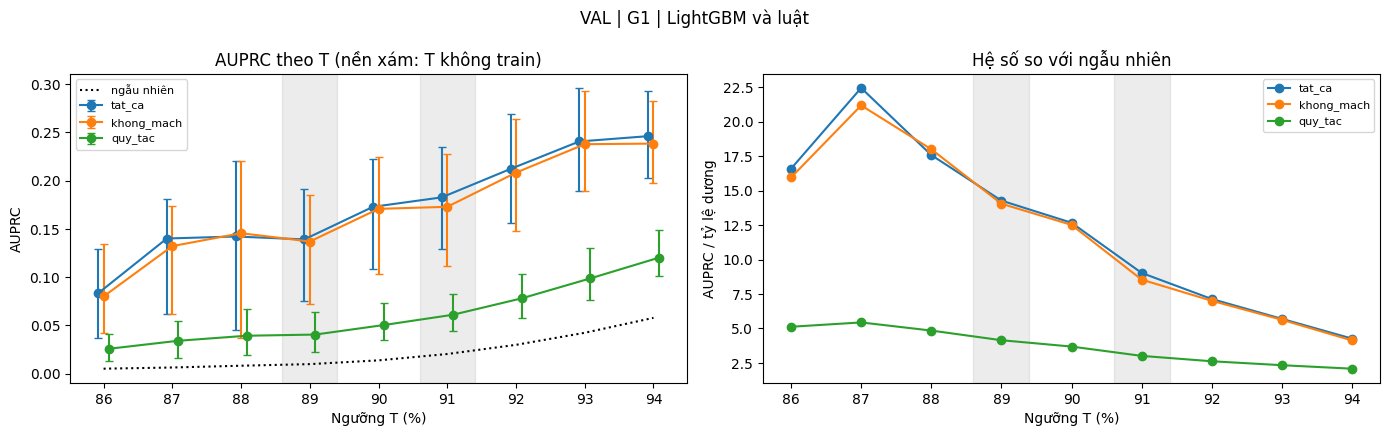

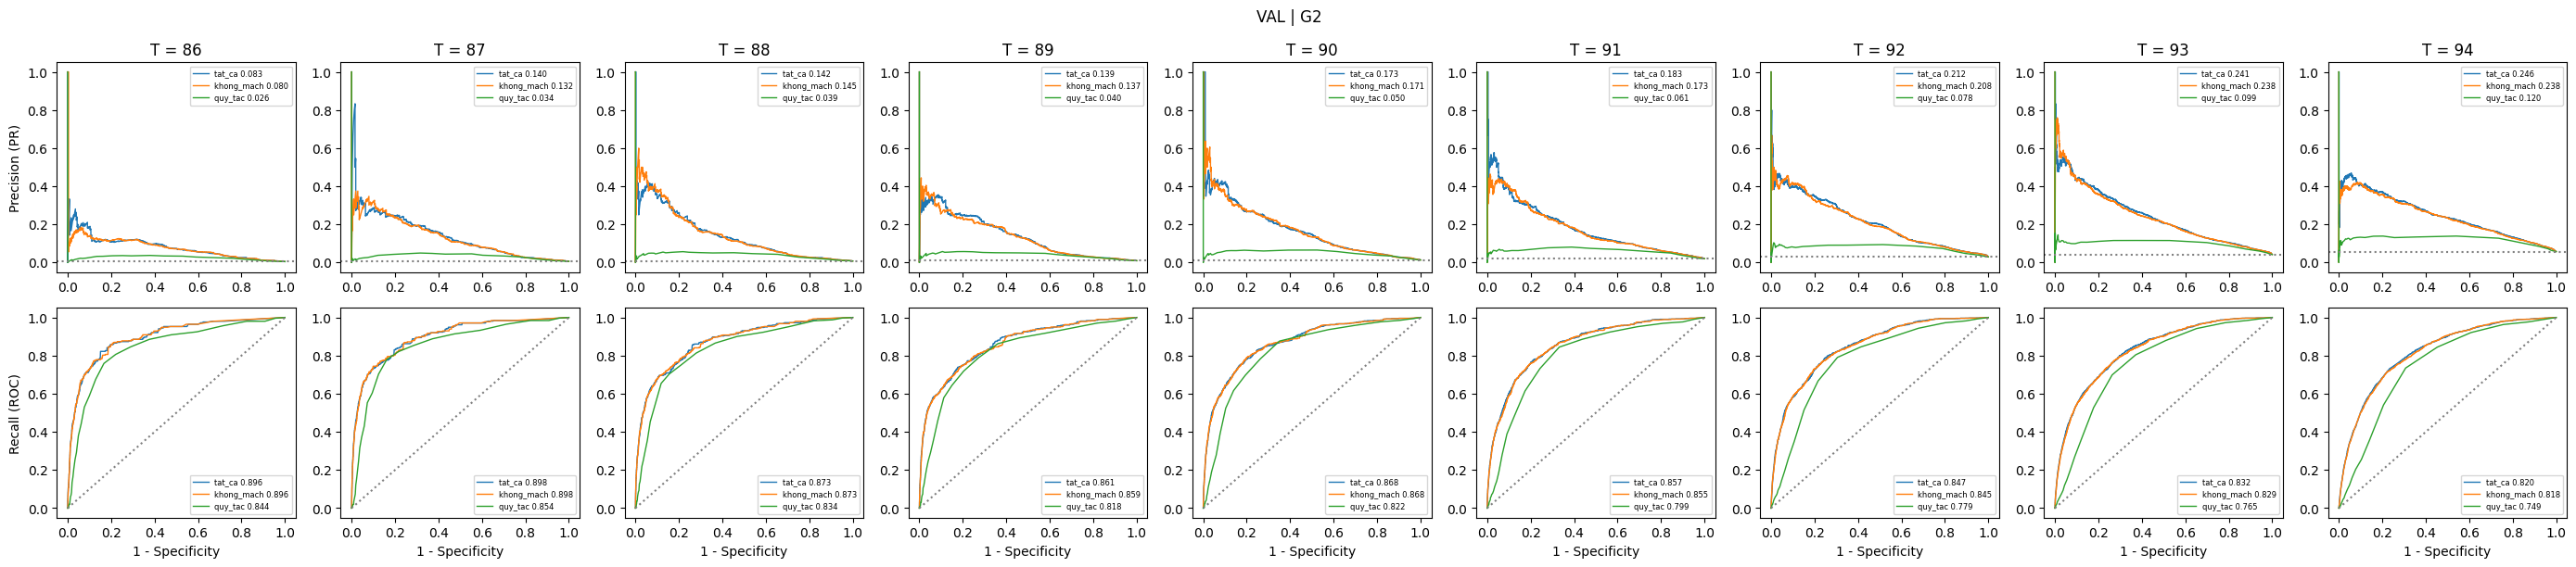

Vi phạm đơn điệu (phải bằng 0 với LightGBM có ràng buộc):


,adjacent,all_pairs,windows_any,max_drop
tat_ca,0.0,0.0,0.0,0.0
khong_mach,0.0,0.0,0.0,0.0


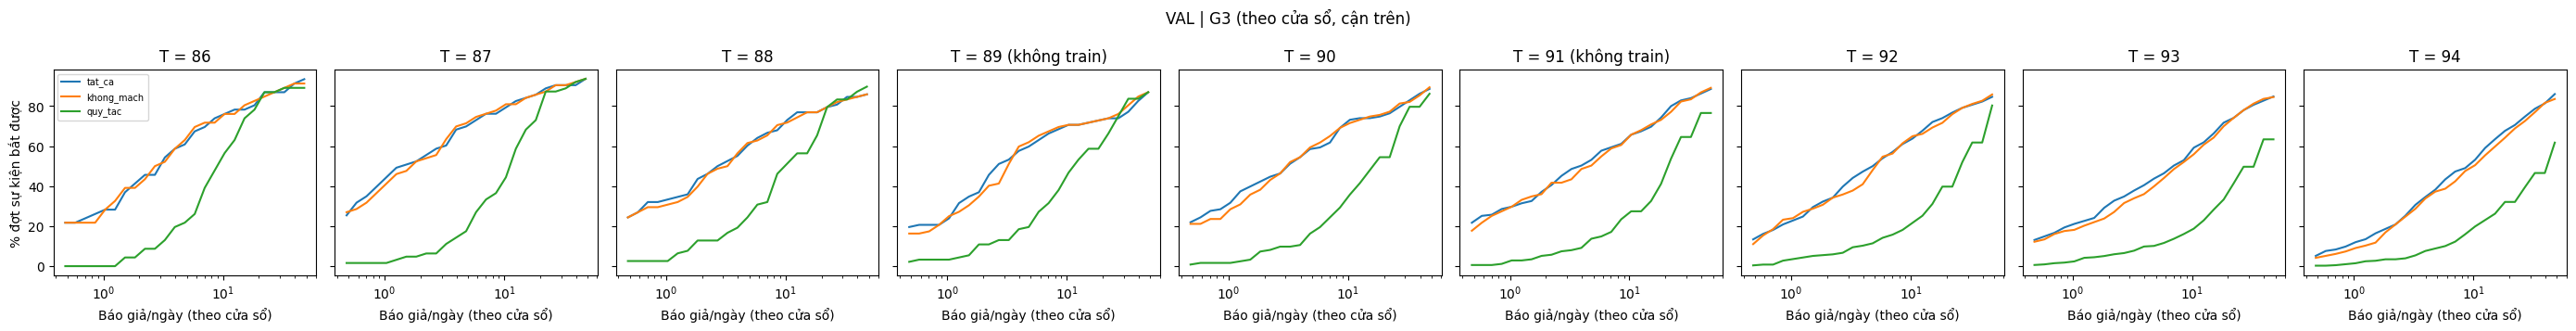

In [4]:
dv = DS["val"]
R = pd.concat([E.by_T(n, S, dv, T_LIST, holdout=T_HO) for n, S in SC["val"].items()], ignore_index=True)
display(R.pivot(index="T", columns="model", values="AUPRC").round(4))
E.plot_auprc_by_T(R, T_HO, "VAL | G1 | LightGBM và luật")
E.plot_pr_roc_by_T(SC["val"], dv, T_LIST, "VAL | G2")
print("Vi phạm đơn điệu (phải bằng 0 với LightGBM có ràng buộc):")
display(pd.DataFrame({n: E.monotonic_report(S, T_LIST) for n, S in SC["val"].items() if n != "quy_tac"}).T)

fas = np.geomspace(0.02, 2, 25); fig, ax = plt.subplots(1, len(T_LIST), figsize=(3.1 * len(T_LIST), 3.6), sharey=True)
for a, T in zip(ax, T_LIST):
    j = C.col(dv, T); ok = dv["OK"][:, j]; y = dv["Y"][ok, j]; ep = E.episode_ids(y, dv["rec"][ok], dv["start"][ok]); hrs = E.neg_hours(y)
    for n, S in SC["val"].items():
        s = S[ok, j]; pe = ep >= 0
        rec_ = [pd.Series((s > E.thr_for_fa(s, y, f))[pe]).groupby(ep[pe]).max().mean() for f in fas]
        a.plot(fas * 24, np.array(rec_) * 100, label=n)
    a.set(xscale="log", xlabel="Báo giả/ngày (theo cửa sổ)", title=f"T = {T}" + (" (không train)" if T in T_HO else ""))
ax[0].set_ylabel("% đợt sự kiện bắt được"); ax[0].legend(fontsize=7); fig.suptitle("VAL | G3 (theo cửa sổ, cận trên)"); plt.tight_layout(); plt.show()

## 4. G11: nhịp tim có giá trị không?
1. Độ quan trọng (gain) từng đặc trưng và gộp theo nhóm (`tc_core.GROUPS`).
2. So AUPRC theo T giữa `tat_ca` và `khong_mach` trên val, kèm khoảng tin cậy của chênh lệch theo bệnh nhân. Khoảng chứa 0 ở hầu hết T thì đặc trưng mạch **không** đóng góp đáng kể trên dữ liệu này.

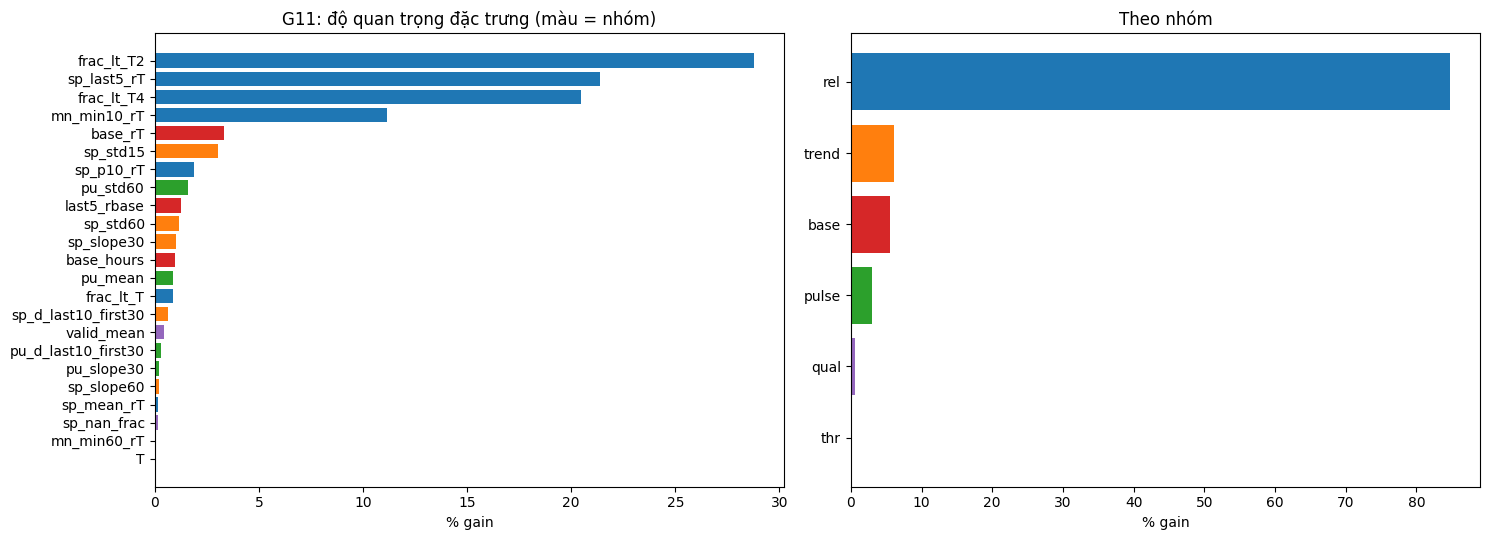

Nhóm mạch chiếm 3.0% tổng gain.


,T,AUPRC_tat_ca,AUPRC_khong_mach,chenh_lo,chenh_hi,ket_luan
0,86,0.0831,0.0799,-0.0183,0.0160,chưa phân biệt
1,87,0.1400,0.1321,-0.0081,0.0170,chưa phân biệt
2,88,0.1421,0.1454,-0.0189,0.0160,chưa phân biệt
3,89,0.1390,0.1368,-0.0089,0.0155,chưa phân biệt
4,90,0.1728,0.1707,-0.0141,0.0173,chưa phân biệt
5,91,0.1826,0.1728,-0.0044,0.0248,chưa phân biệt
6,92,0.2121,0.2083,-0.0118,0.0186,chưa phân biệt
7,93,0.2406,0.2377,-0.0113,0.0171,chưa phân biệt
8,94,0.2461,0.2384,-0.0003,0.0169,chưa phân biệt


In [5]:
b = MODELS["tat_ca"]; imp = pd.Series(b.feature_importance("gain"), index=b.feature_name()); imp = imp / imp.sum() * 100
grp = {c: g for g, cs in C.GROUPS.items() for c in cs}
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
s_ = imp.sort_values(); ax[0].barh(s_.index, s_.values, color=[f"C{list(C.GROUPS).index(grp[c])}" for c in s_.index])
ax[0].set(xlabel="% gain", title="G11: độ quan trọng đặc trưng (màu = nhóm)")
g_ = imp.groupby(imp.index.map(grp)).sum().sort_values(); ax[1].barh(g_.index, g_.values, color=[f"C{list(C.GROUPS).index(g)}" for g in g_.index])
ax[1].set(xlabel="% gain", title="Theo nhóm"); plt.tight_layout(); plt.show()
print(f"Nhóm mạch chiếm {g_.get('pulse', 0):.1f}% tổng gain.")

rows = []
for T in T_LIST:
    j = C.col(dv, T); ok = dv["OK"][:, j]; y = dv["Y"][ok, j]
    lo, hi = E.paired_diff(SC["val"]["tat_ca"][ok, j], SC["val"]["khong_mach"][ok, j], y, dv["pid"][ok])
    rows.append(dict(T=int(T), AUPRC_tat_ca=average_precision_score(y, SC["val"]["tat_ca"][ok, j]),
                     AUPRC_khong_mach=average_precision_score(y, SC["val"]["khong_mach"][ok, j]), chenh_lo=lo, chenh_hi=hi,
                     ket_luan="mạch có ích" if lo > 0 else "mạch có hại" if hi < 0 else "chưa phân biệt"))
display(pd.DataFrame(rows).round(4))